# Project - User Segmentation

In this project, we will answer the questions below
- How can we segment users into relevant groups?

All of the above questions can be answered using User Segmentation

**Dataset source:** https://www.kaggle.com/datasets/minalchoudhary/online-retail-dataset

# Import packages

In [ ]:
# import all packages
import pandas as pd
import numpy as np
import datetime as dt
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import missingno as msno
import pandas as pd
import seaborn as sns
from scipy import stats

os.getcwd()

'/content'

# Import data from CSV to DataFrame

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Analysis/MySkill Project/online_retail_II.xlsx.csv', header=0, encoding='latin1')
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,09-12-2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,09-12-2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,09-12-2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,09-12-2011 12:50,4.95,12680.0,France


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  object 
 1   StockCode    541910 non-null  object 
 2   Description  540456 non-null  object 
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  object 
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


# Data Cleaning

In [ ]:
df_clean = df.copy()
# convert PurchaseDate column to datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], format='%d-%m-%Y %H:%M')

In [ ]:
# make year_month column
df_clean['year_month'] = df_clean['InvoiceDate'].dt.to_period('M')

In [ ]:
# check null data
df_clean.isnull().sum()

,0
Invoice,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
Price,0
Customer ID,135080
Country,0
year_month,0


## Handling Description null data

In [ ]:
# make StockCode mapping to Description
product_dict = (
    df_clean.dropna(subset=["Description"])
    .set_index("StockCode")["Description"]
    .to_dict()
)

# fill null Description
df_clean["Description"] = df_clean["Description"].fillna(df["StockCode"].map(product_dict))

# delete the rest of null data at Description
df_clean = df_clean.dropna(subset=["Description"])

## Handling Customer ID null data

In [ ]:
# calculate null data percentage
print((df_clean.isnull().sum() / len(df)) * 100)

Invoice         0.000000
StockCode       0.000000
Description     0.000000
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    24.905981
Country         0.000000
year_month      0.000000
dtype: float64


<Figure size 1000x600 with 0 Axes>

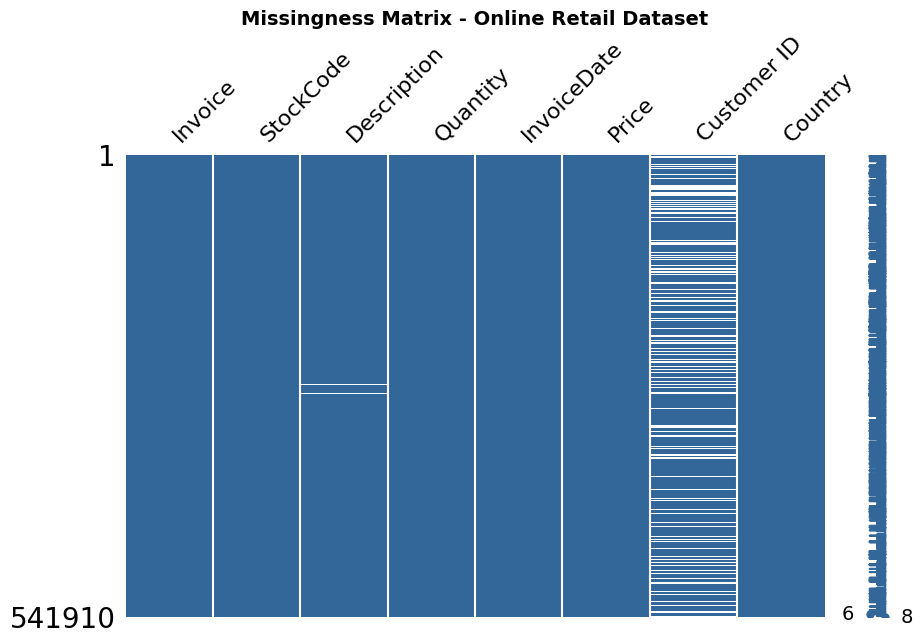

<Figure size 800x600 with 0 Axes>

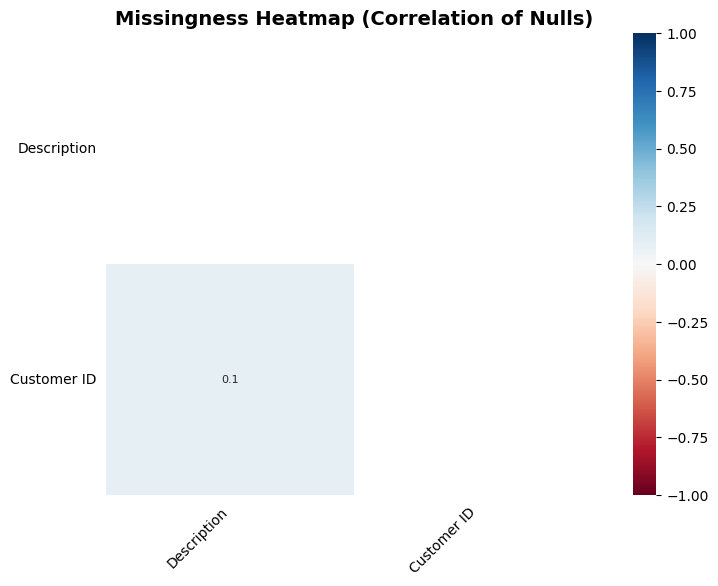

In [ ]:
# Matrix visualize the null position
plt.figure(figsize=(10, 6))
msno.matrix(df, figsize=(10, 6), color=(0.2, 0.4, 0.6))
plt.title(
    "Missingness Matrix - Online Retail Dataset", fontsize=14, fontweight="bold"
)
plt.show()

# Heatmap to check if null column corelated to other null column
plt.figure(figsize=(8, 6))
msno.heatmap(df, figsize=(8, 6), fontsize=10)
plt.title(
    "Missingness Heatmap (Correlation of Nulls)", fontsize=14, fontweight="bold"
)
plt.show()

In [ ]:
# Make a biner column converter for Customer ID, 1 for null, 0 for non-null
df_clean["CustomerID_missing"] = df_clean["Customer ID"].isnull().astype(int)

# Make sure if the null data corelated with 'Country' column
print(
    df_clean.groupby("Country")["CustomerID_missing"]
    .mean()
    .sort_values(ascending=False)
)

Country
Hong Kong               1.000000
Unspecified             0.452915
United Kingdom          0.269473
Israel                  0.158249
Bahrain                 0.105263
EIRE                    0.086750
Switzerland             0.062438
Portugal                0.025675
France                  0.007712
Canada                  0.000000
Australia               0.000000
Brazil                  0.000000
Belgium                 0.000000
Austria                 0.000000
Finland                 0.000000
European Community      0.000000
Greece                  0.000000
Germany                 0.000000
Denmark                 0.000000
Czech Republic          0.000000
Channel Islands         0.000000
Cyprus                  0.000000
Lebanon                 0.000000
Japan                   0.000000
Italy                   0.000000
Iceland                 0.000000
Norway                  0.000000
Lithuania               0.000000
Netherlands             0.000000
Malta                   0.000000
Sa

In [ ]:
df_clean.isnull().sum()

,0
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,134968
Country,0
year_month,0
CustomerID_missing,0


## Delete Negative Quantity

In [ ]:
df_clean['Quantity'].astype(int)

,Quantity
0,6
1,6
2,8
3,6
4,6
...,...
541905,6
541906,4
541907,4
541908,3


In [ ]:
# Show Quantity less than 0 where is represent cancelled
print(df_clean.loc[df['Quantity'] < 0, ['Description', 'Quantity']])

                             Description  Quantity
141                             Discount        -1
154      SET OF 3 COLOURED  FLYING DUCKS        -1
235       PLASTERS IN TIN CIRCUS PARADE        -12
236     PACK OF 12 PINK PAISLEY TISSUES        -24
237     PACK OF 12 BLUE PAISLEY TISSUES        -24
...                                  ...       ...
540449   ZINC T-LIGHT HOLDER STARS SMALL       -11
541541                            Manual        -1
541715        VICTORIAN SEWING BOX LARGE        -5
541716  HANGING HEART JAR T-LIGHT HOLDER        -1
541717     36 PENCILS TUBE RED RETROSPOT        -5

[10527 rows x 2 columns]


In [ ]:
df_clean = df_clean[df_clean['Quantity'] > 0].copy()

In [ ]:
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year_month,CustomerID_missing
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0


## Membuat nilai amount

In [ ]:
df_clean['amount'] = df_clean['Quantity'] * df_clean['Price']

## Delete outlier

In [ ]:
# Delete outlier
df_clean = df_clean[(np.abs(stats.zscore(df_clean[['Quantity','amount']]))<3).all(axis=1)]
df_clean = df_clean.reset_index(drop=True)
df_clean

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year_month,CustomerID_missing,amount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12,0,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12,0,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0,20.34
...,...,...,...,...,...,...,...,...,...,...,...
530443,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011-12,0,12.60
530444,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011-12,0,16.60
530445,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011-12,0,16.60
530446,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011-12,0,14.85


## Convert some of data type

In [ ]:
df_clean['Customer ID'] = df_clean['Customer ID'].astype(str)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530448 entries, 0 to 530447
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Invoice             530448 non-null  object        
 1   StockCode           530448 non-null  object        
 2   Description         530448 non-null  object        
 3   Quantity            530448 non-null  int64         
 4   InvoiceDate         530448 non-null  datetime64[ns]
 5   Price               530448 non-null  float64       
 6   Customer ID         530448 non-null  object        
 7   Country             530448 non-null  object        
 8   year_month          530448 non-null  period[M]     
 9   CustomerID_missing  530448 non-null  int64         
 10  amount              530448 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(5), period[M](1)
memory usage: 44.5+ MB


## Use only 2011 data

In [ ]:
# Filter df_user_monthly to only include transactions from 2011
df_clean = df_clean[df_clean['year_month'].dt.year == 2011].copy()

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 488844 entries, 41604 to 530447
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Invoice             488844 non-null  object        
 1   StockCode           488844 non-null  object        
 2   Description         488844 non-null  object        
 3   Quantity            488844 non-null  int64         
 4   InvoiceDate         488844 non-null  datetime64[ns]
 5   Price               488844 non-null  float64       
 6   Customer ID         488844 non-null  object        
 7   Country             488844 non-null  object        
 8   year_month          488844 non-null  period[M]     
 9   CustomerID_missing  488844 non-null  int64         
 10  amount              488844 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(5), period[M](1)
memory usage: 44.8+ MB


# Creating RFM Segmentation

## Aggregate transaction data into a summary of total transactions (orders), total order value, and the date of the most recent order for each user

In [ ]:
df_user = df_clean.groupby('Customer ID', as_index=False).agg(order_cnt=('Customer ID','count'),max_order_date=('InvoiceDate','max'),total_order_value=('amount','sum'))
df_user

,Customer ID,order_cnt,max_order_date,total_order_value
0,12347.0,151,2011-12-07 15:52:00,3598.21
1,12348.0,14,2011-09-25 13:13:00,904.44
2,12349.0,73,2011-11-21 09:51:00,1757.55
3,12350.0,17,2011-02-02 16:01:00,334.40
4,12352.0,85,2011-11-03 14:37:00,2506.04
...,...,...,...,...
4200,18281.0,7,2011-06-12 10:53:00,80.82
4201,18282.0,12,2011-12-02 11:43:00,178.05
4202,18283.0,756,2011-12-06 12:02:00,2094.88
4203,18287.0,70,2011-10-28 09:29:00,1837.28


## Create a column showing the number of days since the last order

In [ ]:
today = df_clean['InvoiceDate'].max()
df_user['day_since_last_order'] = (today - df_user['max_order_date']).dt.days
df_user

,Customer ID,order_cnt,max_order_date,total_order_value,day_since_last_order
0,12347.0,151,2011-12-07 15:52:00,3598.21,1
1,12348.0,14,2011-09-25 13:13:00,904.44,74
2,12349.0,73,2011-11-21 09:51:00,1757.55,18
3,12350.0,17,2011-02-02 16:01:00,334.40,309
4,12352.0,85,2011-11-03 14:37:00,2506.04,35
...,...,...,...,...,...
4200,18281.0,7,2011-06-12 10:53:00,80.82,180
4201,18282.0,12,2011-12-02 11:43:00,178.05,7
4202,18283.0,756,2011-12-06 12:02:00,2094.88,3
4203,18287.0,70,2011-10-28 09:29:00,1837.28,42


In [ ]:
df_user.describe()

,order_cnt,max_order_date,total_order_value,day_since_last_order
count,4205.000000,4205,4.205000e+03,4205.000000
mean,116.253032,2011-09-16 03:05:07.291319808,2.067027e+03,83.893698
min,1.000000,2011-01-04 11:42:00,2.900000e+00,0.000000
25%,17.000000,2011-08-03 13:50:00,3.022000e+02,16.000000
50%,40.000000,2011-10-23 13:49:00,6.588800e+02,46.000000
75%,97.000000,2011-11-22 13:41:00,1.592120e+03,127.000000
max,117730.000000,2011-12-09 12:50:00,1.362899e+06,339.000000
std,1827.418869,NaN,2.194186e+04,90.114988


## Create bins based on the number of days since the last order, consisting of 5 bins with the following thresholds: min, P20, P40, P60, P80, and max. Label the bins 1 through 5 from highest to lowest as the recency score.

In [ ]:
df_user['recency_score'] = pd.cut(df_user['day_since_last_order'],
                                  bins=[df_user['day_since_last_order'].min(),
                                        np.percentile(df_user['day_since_last_order'], 20),
                                        np.percentile(df_user['day_since_last_order'], 40),
                                        np.percentile(df_user['day_since_last_order'], 60),
                                        np.percentile(df_user['day_since_last_order'], 80),
                                        df_user['day_since_last_order'].max()],
                                  labels=[5, 4, 3, 2, 1],
                                  include_lowest=True).astype(int)
df_user

,Customer ID,order_cnt,max_order_date,total_order_value,day_since_last_order,recency_score
0,12347.0,151,2011-12-07 15:52:00,3598.21,1,5
1,12348.0,14,2011-09-25 13:13:00,904.44,74,2
2,12349.0,73,2011-11-21 09:51:00,1757.55,18,4
3,12350.0,17,2011-02-02 16:01:00,334.40,309,1
4,12352.0,85,2011-11-03 14:37:00,2506.04,35,3
...,...,...,...,...,...,...
4200,18281.0,7,2011-06-12 10:53:00,80.82,180,1
4201,18282.0,12,2011-12-02 11:43:00,178.05,7,5
4202,18283.0,756,2011-12-06 12:02:00,2094.88,3,5
4203,18287.0,70,2011-10-28 09:29:00,1837.28,42,3


In [ ]:
df_user.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4205 entries, 0 to 4204
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer ID           4205 non-null   object        
 1   order_cnt             4205 non-null   int64         
 2   max_order_date        4205 non-null   datetime64[ns]
 3   total_order_value     4205 non-null   float64       
 4   day_since_last_order  4205 non-null   int64         
 5   recency_score         4205 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 197.2+ KB


## Create bins for the total transactions (orders) consisting of 5 bins with the following thresholds: min, P20, P40, P60, P80, and max, and label them 1 through 5 from the lowest bin to the highest as the frequency score.

In [ ]:
df_user['frequency_score'] = pd.cut(df_user['order_cnt'],
                                    bins=[df_user['order_cnt'].min(),
                                          np.percentile(df_user['order_cnt'], 20),
                                          np.percentile(df_user['order_cnt'], 40),
                                          np.percentile(df_user['order_cnt'], 60),
                                          np.percentile(df_user['order_cnt'], 80),
                                          df_user['order_cnt'].max()],
                                    labels=[1, 2, 3, 4, 5],
                                    include_lowest=True).astype(int)
df_user

,Customer ID,order_cnt,max_order_date,total_order_value,day_since_last_order,recency_score,frequency_score
0,12347.0,151,2011-12-07 15:52:00,3598.21,1,5,5
1,12348.0,14,2011-09-25 13:13:00,904.44,74,2,1
2,12349.0,73,2011-11-21 09:51:00,1757.55,18,4,4
3,12350.0,17,2011-02-02 16:01:00,334.40,309,1,2
4,12352.0,85,2011-11-03 14:37:00,2506.04,35,3,4
...,...,...,...,...,...,...,...
4200,18281.0,7,2011-06-12 10:53:00,80.82,180,1,1
4201,18282.0,12,2011-12-02 11:43:00,178.05,7,5,1
4202,18283.0,756,2011-12-06 12:02:00,2094.88,3,5,5
4203,18287.0,70,2011-10-28 09:29:00,1837.28,42,3,4


In [ ]:
df_user.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4205 entries, 0 to 4204
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer ID           4205 non-null   object        
 1   order_cnt             4205 non-null   int64         
 2   max_order_date        4205 non-null   datetime64[ns]
 3   total_order_value     4205 non-null   float64       
 4   day_since_last_order  4205 non-null   int64         
 5   recency_score         4205 non-null   int64         
 6   frequency_score       4205 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(4), object(1)
memory usage: 230.1+ KB


## Create bins for the total order value consisting of 5 bins with the following thresholds: min, P20, P40, P60, P80, and max, and label them 1 through 5 from the lowest to the highest bin as a monetary score.

In [ ]:
df_user['monetary_score'] = pd.cut(df_user['total_order_value'],
                                   bins=[df_user['total_order_value'].min(),
                                         np.percentile(df_user['total_order_value'], 20),
                                         np.percentile(df_user['total_order_value'], 40),
                                         np.percentile(df_user['total_order_value'], 60),
                                         np.percentile(df_user['total_order_value'], 80),
                                         df_user['total_order_value'].max()],
                                   labels=[1, 2, 3, 4, 5],
                                   include_lowest=True).astype(int)
df_user

,Customer ID,order_cnt,max_order_date,total_order_value,day_since_last_order,recency_score,frequency_score,monetary_score
0,12347.0,151,2011-12-07 15:52:00,3598.21,1,5,5,5
1,12348.0,14,2011-09-25 13:13:00,904.44,74,2,1,3
2,12349.0,73,2011-11-21 09:51:00,1757.55,18,4,4,4
3,12350.0,17,2011-02-02 16:01:00,334.40,309,1,2,2
4,12352.0,85,2011-11-03 14:37:00,2506.04,35,3,4,5
...,...,...,...,...,...,...,...,...
4200,18281.0,7,2011-06-12 10:53:00,80.82,180,1,1,1
4201,18282.0,12,2011-12-02 11:43:00,178.05,7,5,1,1
4202,18283.0,756,2011-12-06 12:02:00,2094.88,3,5,5,5
4203,18287.0,70,2011-10-28 09:29:00,1837.28,42,3,4,4


In [ ]:
df_user.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4205 entries, 0 to 4204
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer ID           4205 non-null   object        
 1   order_cnt             4205 non-null   int64         
 2   max_order_date        4205 non-null   datetime64[ns]
 3   total_order_value     4205 non-null   float64       
 4   day_since_last_order  4205 non-null   int64         
 5   recency_score         4205 non-null   int64         
 6   frequency_score       4205 non-null   int64         
 7   monetary_score        4205 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(5), object(1)
memory usage: 262.9+ KB


## Create a column for segment names based on recency and frequency scores

In [ ]:
df_user['segment'] = np.select(
    [(df_user['recency_score']==5) & (df_user['frequency_score']>=4),
     (df_user['recency_score'].between(3, 4)) & (df_user['frequency_score']>=4),
     (df_user['recency_score']>=4) & (df_user['frequency_score'].between(2, 3)),
     (df_user['recency_score']<=2) & (df_user['frequency_score']==5),
     (df_user['recency_score']==3) & (df_user['frequency_score']==3),
     (df_user['recency_score']==5) & (df_user['frequency_score']==1),
     (df_user['recency_score']==4) & (df_user['frequency_score']==1),
     (df_user['recency_score']<=2) & (df_user['frequency_score'].between(3, 4)),
     (df_user['recency_score']==3) & (df_user['frequency_score']<=2),
     (df_user['recency_score']<=2) & (df_user['frequency_score']<=2)],
    ['01-Champion', '02-Loyal Customers', '03-Potential Loyalists', "04-Can't Lose Them", '05-Need Attention',
     '06-New Customers', '07-Promising', '08-At Risk', '09-About to Sleep', '10-Hibernating'],
    default='Unknown'
)

df_user

,Customer ID,order_cnt,max_order_date,total_order_value,day_since_last_order,recency_score,frequency_score,monetary_score,segment
0,12347.0,151,2011-12-07 15:52:00,3598.21,1,5,5,5,01-Champion
1,12348.0,14,2011-09-25 13:13:00,904.44,74,2,1,3,10-Hibernating
2,12349.0,73,2011-11-21 09:51:00,1757.55,18,4,4,4,02-Loyal Customers
3,12350.0,17,2011-02-02 16:01:00,334.40,309,1,2,2,10-Hibernating
4,12352.0,85,2011-11-03 14:37:00,2506.04,35,3,4,5,02-Loyal Customers
...,...,...,...,...,...,...,...,...,...
4200,18281.0,7,2011-06-12 10:53:00,80.82,180,1,1,1,10-Hibernating
4201,18282.0,12,2011-12-02 11:43:00,178.05,7,5,1,1,06-New Customers
4202,18283.0,756,2011-12-06 12:02:00,2094.88,3,5,5,5,01-Champion
4203,18287.0,70,2011-10-28 09:29:00,1837.28,42,3,4,4,02-Loyal Customers


In [ ]:
df_user.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4205 entries, 0 to 4204
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer ID           4205 non-null   object        
 1   order_cnt             4205 non-null   int64         
 2   max_order_date        4205 non-null   datetime64[ns]
 3   total_order_value     4205 non-null   float64       
 4   day_since_last_order  4205 non-null   int64         
 5   recency_score         4205 non-null   int64         
 6   frequency_score       4205 non-null   int64         
 7   monetary_score        4205 non-null   int64         
 8   segment               4205 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(5), object(2)
memory usage: 295.8+ KB


## Display a summary of the RFM segmentation (point 8), showing the number of users, the average and median total order value, and the number of days since the last order

In [ ]:
summary = pd.pivot_table(df_user, index='segment',
               values=['Customer ID','day_since_last_order','order_cnt','total_order_value'],
               aggfunc={'Customer ID': pd.Series.nunique,
                        'day_since_last_order': [np.mean, np.median],
                        'order_cnt': [np.mean, np.median],
                        'total_order_value': [np.mean, np.median]})

summary['pct_unique'] = (summary['Customer ID'] / summary['Customer ID'].sum() * 100).round(1)
summary

/tmp/ipykernel_1104/640043600.py:1: FutureWarning: The provided callable <function mean at 0x7e86b1f85b20> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  summary = pd.pivot_table(df_user, index='segment',
/tmp/ipykernel_1104/640043600.py:1: FutureWarning: The provided callable <function median at 0x7e86af3dcf40> is currently using SeriesGroupBy.median. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "median" instead.
  summary = pd.pivot_table(df_user, index='segment',


Customer ID day_since_last_order          order_cnt  \
                           nunique                 mean median        mean   
segment                                                                      
01-Champion                    579             4.704663    4.0  480.507772   
02-Loyal Customers             806            31.635236   28.0  150.997519   
03-Potential Loyalists         492            14.729675   15.0   34.085366   
04-Can't Lose Them              75           125.426667  106.0  177.173333   
05-Need Attention              182            47.752747   46.0   41.357143   
06-New Customers                57             6.035088    7.0    7.561404   
07-Promising                   105            21.247619   21.0    7.638095   
08-At Risk                     552           147.914855  128.0   55.735507   
09-About to Sleep              313            49.386581   50.0   16.006390   
10-Hibernating                1044           191.114943  190.0   13.727969   

                              total_order_value           pct_unique  
                       median              mean    median             
segment                                                               
01-Champion             163.0       8270.729413  2578.090       13.8  
02-Loyal Customers      113.0       2594.914194  1704.415       19.2  
03-Potential Loyalists   33.0        813.809675   598.055       11.7  
04-Can't Lose Them      155.0       2188.798680  2037.080        1.8  
05-Need Attention        40.0        786.029786   653.380        4.3  
06-New Customers          9.0        286.131228   204.000        1.4  
07-Promising              8.0        318.938857   192.600        2.5  
08-At Risk               50.0        993.171938   778.090       13.1  
09-About to Sleep        16.0        414.904409   325.910        7.4  
10-Hibernating           13.0        360.238910   269.490       24.8